# Homework Assignment: GCN for Node Classification and Imputation


In [1]:
!pip uninstall -y numpy pandas xarray mizani plotnine arviz || true
!pip install "numpy==1.26.4" "pandas==2.2.2"


Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
Found existing installation: pandas 2.2.2
Uninstalling pandas-2.2.2:
  Successfully uninstalled pandas-2.2.2
  Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl.metadata (61 kB)
  Using cached pandas-2.2.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (19 kB)
Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl (13.7 MB)
Using cached pandas-2.2.2-cp312-cp312-macosx_11_0_arm64.whl (11.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]


If you are working on colab, you will be prompted to restart the session. Please do that so that correct version of `numpy` is picked up in the next cells.

In [2]:
!pip install -q leidenalg igraph scanpy phate scprep magic-impute
!pip install torch torch-geometric  -q
# !wget https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_10k_v3/pbmc_10k_v3_filtered_feature_bc_matrix.h5

In [3]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from torch_geometric.nn import MessagePassing
from torch_geometric.utils import add_self_loops, degree
from torch_geometric.data import Data
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import kneighbors_graph
import seaborn as sns
import magic
import phate
import scprep

print("PyTorch version:", torch.__version__)
print("PyTorch Geometric available:", True)
print("Setup complete!")


/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


PyTorch version: 2.9.0
PyTorch Geometric available: True
Setup complete!


## Load PBMC12k Data from Scanpy

In [4]:
adata = sc.read_10x_h5('pbmc_10k_v3_filtered_feature_bc_matrix.h5')

print(f"Dataset shape: {adata.shape}")
print(f"Number of cells: {adata.n_obs}")
print(f"Number of genes: {adata.n_vars}")
print(f"\nFirst few gene names: {adata.var_names[:5].tolist()}")

# Basic preprocessing
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
print(f"\nAfter filtering - Cells: {adata.n_obs}, Genes: {adata.n_vars}")

# Normalize and log-transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Select highly variable genes
sc.pp.highly_variable_genes(adata, n_top_genes=500)
adata = adata[:, adata.var.highly_variable]
print(f"After selecting highly variable genes: {adata.n_vars} genes")

# Perform PCA for downstream analysis
sc.tl.pca(adata, n_comps=50)
print("\nPCA completed with 50 components")

# Compute cell type annotations (clustering)
sc.pp.neighbors(adata, n_neighbors=10)
sc.tl.leiden(adata, resolution=0.5)
print(f"Number of cell clusters identified: {adata.obs['leiden'].nunique()}")

# Display cell type distribution
print("\nCell type distribution:")
print(adata.obs['leiden'].value_counts().sort_index())

/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/anndata/_core/anndata.py:1794: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/anndata/_core/anndata.py:1794: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Dataset shape: (11769, 33538)
Number of cells: 11769
Number of genes: 33538

First few gene names: ['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3']


/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/anndata/_core/anndata.py:1794: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/anndata/_core/anndata.py:1794: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")



After filtering - Cells: 11537, Genes: 20292
After selecting highly variable genes: 500 genes


/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:245: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  Version(ad.__version__) < Version("0.9")
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:385: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scanpy/neighbors/__init__.py:430: FutureWarning: Use obsm (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`) instead of AnnData.obsm_keys, AnnData.obsm_keys is deprecated and will be removed in the future.
  if "X_diffmap" in adata.obsm_keys():



PCA completed with 50 components


/var/folders/yn/wwd5hg1s66g4gjp_60m2465m0000gn/T/ipykernel_29768/2553123689.py:28: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=0.5)


Number of cell clusters identified: 13

Cell type distribution:
leiden
0     3268
1     3050
2     1445
3      982
4      647
5      632
6      488
7      404
8      244
9      181
10      82
11      70
12      44
Name: count, dtype: int64


## Building a Graph from Data

In [5]:
print("\n--- Building Graph from Single-Cell Data ---")

# TODO: Experiment with different k values for k-NN graph construction
k_neighbors = 3

# Use PCA representation for building the graph
X = adata.obsm['X_pca'][:, :30]  # Use first 30 PCs

# TODO: Build k-NN graph
print(f"Building k-NN graph with k={k_neighbors}...")
adjacency_matrix = kneighbors_graph(X, n_neighbors=k_neighbors, mode='connectivity', include_self=True) #use kneighbors_graph from sklearn

# TODO: Convert to edge index format (COO format)
adjacency_matrix = adjacency_matrix.tocoo()
edge_index = torch.tensor([adjacency_matrix.row, adjacency_matrix.col], dtype=torch.long) #Convert to PyG edge_index format

print(f"Number of edges: {edge_index.shape[1]}")
print(f"Edge index shape: {edge_index.shape}")

# Prepare node features (use highly variable genes)
node_features = torch.tensor(adata.X.toarray(), dtype=torch.float)
print(f"Node features shape: {node_features.shape}")

# TODO: Prepare labels (cell type annotations)
labels = torch.tensor(adata.obs['leiden'].astype('category').cat.codes.values, dtype=torch.long)
num_classes = labels.max().item() + 1  # Find unique cell types
print(f"Number of classes: {num_classes}")

# Create train/test/validation masks
train_idx, temp_idx = train_test_split(np.arange(len(labels)), test_size=0.4, random_state=42, stratify=labels.numpy())
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=42, stratify=labels[temp_idx].numpy())

train_mask = torch.zeros(len(labels), dtype=torch.bool)
val_mask = torch.zeros(len(labels), dtype=torch.bool)
test_mask = torch.zeros(len(labels), dtype=torch.bool)

train_mask[train_idx] = True
val_mask[val_idx] = True
test_mask[test_idx] = True

print(f"\nTrain nodes: {train_mask.sum()}")
print(f"Validation nodes: {val_mask.sum()}")
print(f"Test nodes: {test_mask.sum()}")

# Create PyTorch Geometric Data object
data = Data(x=node_features, edge_index=edge_index, y=labels)
data.train_mask = train_mask
data.val_mask = val_mask
data.test_mask = test_mask

print("\nGraph data object created:")
print(data)


--- Building Graph from Single-Cell Data ---
Building k-NN graph with k=3...
Number of edges: 34611
Edge index shape: torch.Size([2, 34611])
Node features shape: torch.Size([11537, 500])
Number of classes: 13

Train nodes: 6922
Validation nodes: 2307
Test nodes: 2308

Graph data object created:
Data(x=[11537, 500], edge_index=[2, 34611], y=[11537], train_mask=[11537], val_mask=[11537], test_mask=[11537])


/var/folders/yn/wwd5hg1s66g4gjp_60m2465m0000gn/T/ipykernel_29768/2328880497.py:15: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:256.)
  edge_index = torch.tensor([adjacency_matrix.row, adjacency_matrix.col], dtype=torch.long) #Convert to PyG edge_index format


## Build a GCN

In [6]:
# Standard GCN Convolutional layer from Kipf & Welling
class GCNConv(MessagePassing):
    def __init__(self, in_channels, out_channels):
        super(GCNConv, self).__init__(aggr='add')  # "Add" aggregation (Step 5).
        self.lin = torch.nn.Linear(in_channels, out_channels)

    def forward(self, x, edge_index):
        # x has shape [N, in_channels]
        # edge_index has shape [2, E]

        # Step 1: Add self-loops to the adjacency matrix.
        edge_index, _ = add_self_loops(edge_index, num_nodes=x.size(0))

        # Step 2: Linearly transform node feature matrix.
        x = self.lin(x)

        # Step 3: Compute normalization.
        row, col = edge_index
        deg = degree(col, x.size(0), dtype=x.dtype)
        deg_inv_sqrt = deg.pow(-0.5)
        deg_inv_sqrt[deg_inv_sqrt == float('inf')] = 0
        norm = deg_inv_sqrt[row] * deg_inv_sqrt[col]

        # Step 4-5: Start propagating messages.
        return self.propagate(edge_index, x=x, norm=norm)

    def message(self, x_j, norm):
        # x_j has shape [E, out_channels]
        # Step 4: Normalize node features.
        return norm.view(-1, 1) * x_j

In [7]:
class GCNModel(torch.nn.Module):
    def __init__(self, num_node_features, hidden_features, output_features):
        super(GCNModel, self).__init__()
        self.conv1 = GCNConv(num_node_features, hidden_features)
        self.conv2 = GCNConv(hidden_features, hidden_features)
        self.conv3 = GCNConv(hidden_features, output_features)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        x = self.conv3(x, edge_index)
        return x

# Build a `BetterGCN`

In [8]:
# TODO: Adapt the GCNConv class with the modifications suggested by the pset. Refer to https://pytorch-geometric.readthedocs.io/en/latest/notes/create_gnn.html for details on the MessagePassing class
class BetterGCNConv(MessagePassing):
    def __init__(self, in_channels, out_channels, hidden=None):
        super(BetterGCNConv, self).__init__(aggr='add')  # "Add" aggregation (Step 5).
        self.lin = torch.nn.Linear(in_channels, out_channels)

        # MLP for the message transformation γ; input is concat([x_i, x_j])
        hid = hidden or max(out_channels, 64)
        self.mlp = nn.Sequential(
            nn.Linear(2 * out_channels, hid),
            nn.ReLU(),
            nn.Linear(hid, out_channels)
        )

    def forward(self, x, edge_index):
        # x has shape [N, in_channels]
        # edge_index has shape [2, E]

        # Step 1: Add self-loops to the adjacency matrix.
        edge_index, _ = add_self_loops(edge_index, num_nodes=x.size(0))

        # Step 2: Linearly transform node feature matrix.
        x = self.lin(x)

        # Step 3: Start propagating messages.
        return self.propagate(edge_index, x=x)

    def message(self, x_j, x_i):
        # x_j. x_i both have shape [E, out_channels]
        # Build message via MLP γ(concat(x_i, x_j))
        msg = torch.cat([x_i, x_j], dim=-1)
        return self.mlp(msg)

In [9]:
# TODO: Adapt the GCNModel class with BetterGCNConv
class BetterGCNModel(torch.nn.Module):
    def __init__(self, num_node_features, hidden_features, output_features):
        super(BetterGCNModel, self).__init__()
        self.conv1 = BetterGCNConv(num_node_features, hidden_features)
        self.conv2 = BetterGCNConv(hidden_features, hidden_features)
        self.conv3 = BetterGCNConv(hidden_features, output_features)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        x = self.conv3(x, edge_index)
        return x

## Using BetterGCN for Node Classification


Model architecture:
BetterGCNModel(
  (conv1): BetterGCNConv()
  (conv2): BetterGCNConv()
  (conv3): BetterGCNConv()
)

Number of parameters: 64474

--- Training BetterGCN for Node Classification ---
Epoch: 010, Loss: 2.1521, Train Acc: 0.4464, Val Acc: 0.4482, Test Acc: 0.4354
Epoch: 020, Loss: 1.5161, Train Acc: 0.7135, Val Acc: 0.7117, Test Acc: 0.7067
Epoch: 030, Loss: 1.0203, Train Acc: 0.8103, Val Acc: 0.8140, Test Acc: 0.8037
Epoch: 040, Loss: 0.7123, Train Acc: 0.8723, Val Acc: 0.8656, Test Acc: 0.8687
Epoch: 050, Loss: 0.5338, Train Acc: 0.9088, Val Acc: 0.9081, Test Acc: 0.9008
Epoch: 060, Loss: 0.4171, Train Acc: 0.9327, Val Acc: 0.9233, Test Acc: 0.9224
Epoch: 070, Loss: 0.3274, Train Acc: 0.9432, Val Acc: 0.9306, Test Acc: 0.9315
Epoch: 080, Loss: 0.2539, Train Acc: 0.9552, Val Acc: 0.9393, Test Acc: 0.9415
Epoch: 090, Loss: 0.2184, Train Acc: 0.9705, Val Acc: 0.9523, Test Acc: 0.9450
Epoch: 100, Loss: 0.1927, Train Acc: 0.9788, Val Acc: 0.9593, Test Acc: 0.9562
Epoch: 11

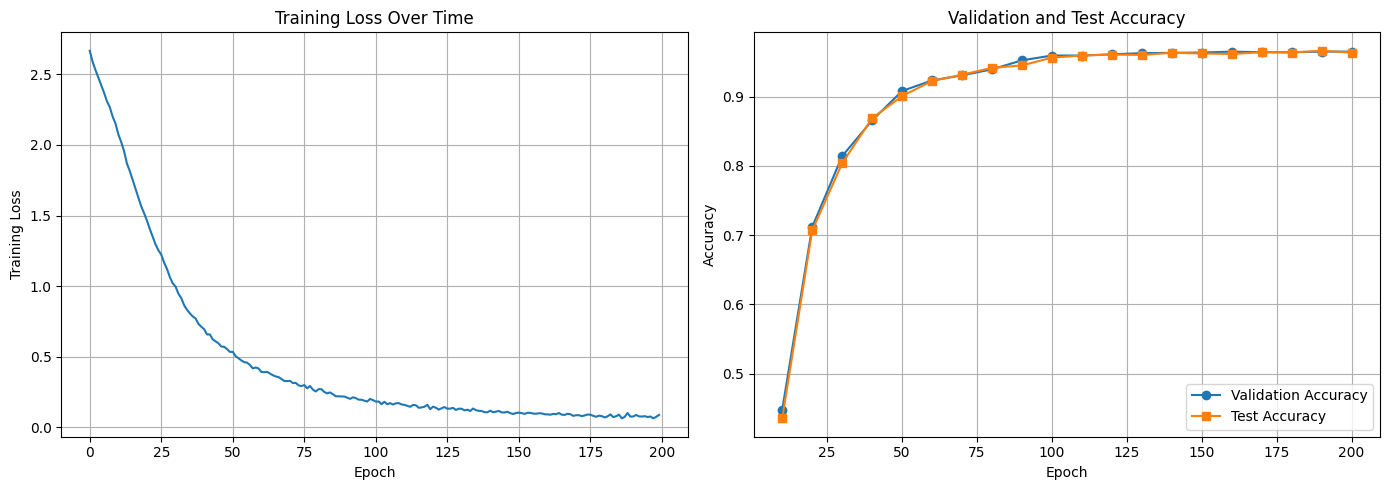

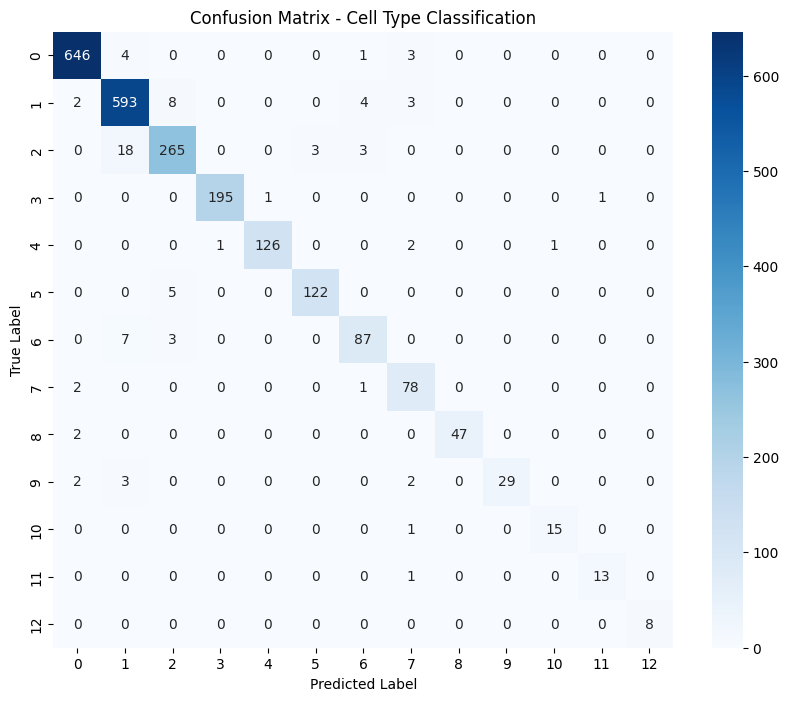


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       654
           1       0.95      0.97      0.96       610
           2       0.94      0.92      0.93       289
           3       0.99      0.99      0.99       197
           4       0.99      0.97      0.98       130
           5       0.98      0.96      0.97       127
           6       0.91      0.90      0.90        97
           7       0.87      0.96      0.91        81
           8       1.00      0.96      0.98        49
           9       1.00      0.81      0.89        36
          10       0.94      0.94      0.94        16
          11       0.93      0.93      0.93        14
          12       1.00      1.00      1.00         8

    accuracy                           0.96      2308
   macro avg       0.96      0.95      0.95      2308
weighted avg       0.96      0.96      0.96      2308



In [10]:
# TODO: Initialize model
num_features = data.x.shape[1]
hidden_dim = 64
num_classes = len(torch.unique(data.y))

model = BetterGCNModel(num_features, hidden_dim, num_classes) # Initialize the BetterGCNModel

print(f"\nModel architecture:")
print(model)
print(f"\nNumber of parameters: {sum(p.numel() for p in model.parameters())}")

# TODO: Experiment with different optimizers and learning rates
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #Initialize an Adam optimizer
criterion = torch.nn.CrossEntropyLoss()

# TODO: Training function, do one step of forward pass, calculate loss, back propagate and return loss.
def train():
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

# TODO: Evaluation function, do one evaluation step. Return accuracy.
def evaluate(mask):
    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        correct = (pred[mask] == data.y[mask]).sum()
        acc = int(correct) / int(mask.sum())
    return acc

# Training loop
print("\n--- Training BetterGCN for Node Classification ---")
num_epochs = 200
train_losses = []
val_accs = []
test_accs = []

for epoch in range(1, num_epochs + 1):
    loss = train()
    train_losses.append(loss)

    if epoch % 10 == 0:
        train_acc = evaluate(data.train_mask)
        val_acc = evaluate(data.val_mask)
        test_acc = evaluate(data.test_mask)
        val_accs.append(val_acc)
        test_accs.append(test_acc)

        print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}, Train Acc: {train_acc:.4f}, '
              f'Val Acc: {val_acc:.4f}, Test Acc: {test_acc:.4f}')

# Final evaluation
final_test_acc = evaluate(data.test_mask)
print(f"\n{'='*60}")
print(f"Final Test Accuracy: {final_test_acc:.4f}")
print(f"{'='*60}")

# Visualize training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Training Loss')
ax1.set_title('Training Loss Over Time')
ax1.grid(True)

epochs_recorded = list(range(10, num_epochs + 1, 10))
ax2.plot(epochs_recorded, val_accs, label='Validation Accuracy', marker='o')
ax2.plot(epochs_recorded, test_accs, label='Test Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Validation and Test Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Compute and visualize confusion matrix
model.eval()
with torch.no_grad():
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)

from sklearn.metrics import confusion_matrix, classification_report

y_true = data.y[data.test_mask].numpy()
y_pred = pred[data.test_mask].numpy()

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Cell Type Classification')
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

## Using MAGIC and GCN for Gene Denoising

In [ ]:
# TODO: Initilizae magic and apply it on adata.X
# MAGIC operator has many parameters. See how each of these affects the output.
# You can use this repo for reference: https://github.com/KrishnaswamyLab/MAGIC/blob/master/python/magic/magic.py
"""Set the parameters on this estimator.
        knn : int, optional, default: 5
            number of nearest neighbors on which to build kernel
        t : int, optional, default: 3
            power to which the diffusion operator is powered.
            This sets the level of diffusion. If 'auto', t is selected
            according to the R squared of the diffused data

        n_pca : int, optional, default: 100
            Number of principal components to use for calculating
            neighborhoods. For extremely large datasets, using
            n_pca < 20 allows neighborhoods to be calculated in
            roughly log(n_samples) time."""
magic_operator = magic.MAGIC(knn=5, t=50, n_pca=50)

X_denoised = magic_operator.fit_transform(adata.X.toarray())


Calculating MAGIC...
  Running MAGIC on 11537 cells and 500 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 3.25 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.20 seconds.
    Calculating affinities...
    Calculated affinities in 0.17 seconds.
  Calculated graph and diffusion operator in 3.64 seconds.
  Calculating imputation...
  Calculated imputation in 3.86 seconds.
Calculated MAGIC in 7.50 seconds.


In [21]:
# TODO: Initilizae phate for both the true values and predicted values.
# Similar to MAGIC, PHATE also has many parameters. Change the values and see how each one of them affects the output.
phate_data = phate.PHATE(n_components=2, n_jobs=-1)
phate_denoised = phate.PHATE(n_components=2, n_jobs=-1)
data_2d = phate_data.fit_transform(adata.X.toarray())
denoised_2d = phate_denoised.fit_transform(X_denoised)


Calculating PHATE...
  Running PHATE on 11537 observations and 500 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 3.08 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.27 seconds.
    Calculating affinities...
    Calculated affinities in 0.11 seconds.
  Calculated graph and diffusion operator in 3.48 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.96 seconds.
    Calculating KMeans...
    Calculated KMeans in 3.23 seconds.
  Calculated landmark operator in 4.22 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 5.26 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 1.18 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 3.10 seconds.
Calculated PHATE in 17.60 seconds.
Calculating PHATE...
  Running PHATE on 11537 observations and 500 variables.
  Calculating graph and diffusion o

/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'PHATE: Original Data'}, xlabel='Cluster 1', ylabel='Cluster 2'>

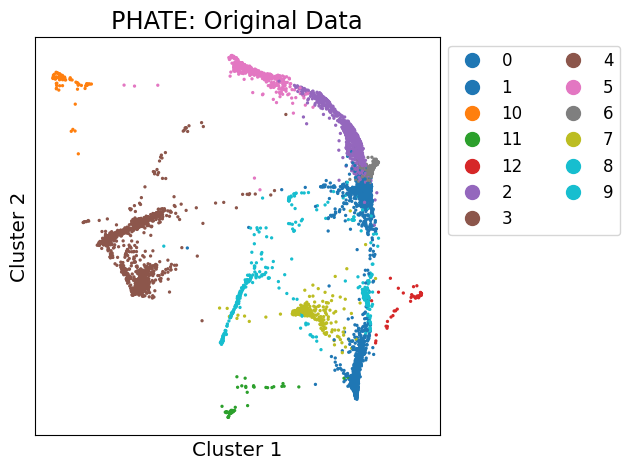

In [14]:
scprep.plot.scatter2d(data_2d, c=adata.obs['leiden'].values,
                      title='PHATE: Original Data',
                      legend_anchor=(1, 1),
                      cmap='tab10',
                      ticks=False,
                      label_prefix='Cluster ')

/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: title={'center': 'PHATE: MAGIC Denoised'}, xlabel='Cluster 1', ylabel='Cluster 2'>

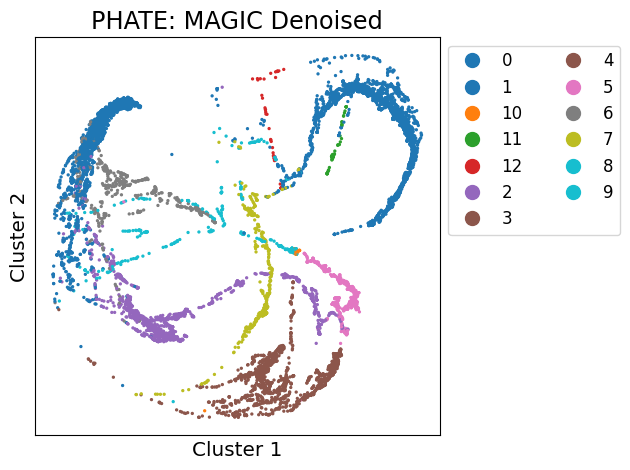

In [22]:
scprep.plot.scatter2d(denoised_2d, c=adata.obs['leiden'].values,
                      title='PHATE: MAGIC Denoised',
                        legend_anchor=(1, 1),
                          cmap='tab10',
                          ticks=False,
                          label_prefix='Cluster ')

Using GCN to impute the genes

In [23]:
print("--- Preparing Data for Gene Imputation Task ---")

#TODO: Play with mask_ratio
mask_ratio = 0.3  # Mask x% of non-zero features


# Create a copy of the original features

original_features = torch.from_numpy(X_denoised).float()

# Create masking indices - ONLY mask non-zero entries
num_nodes, num_features = data.x.shape

# TODO: Find the indices of all non-zero entries in data.x. Hint: Use torch.nonzero() with as_tuple=True to get row and column indices
nonzero_indices = torch.nonzero(data.x, as_tuple=True)
num_nonzero = nonzero_indices[0].size(0)  # Hint: Length of the first element in nonzero_indices tuple

print(f"Total entries: {num_nodes * num_features}")
print(f"Non-zero entries: {num_nonzero}")
print(f"Sparsity: {(1 - num_nonzero / (num_nodes * num_features)) * 100:.2f}%")

# TODO: Calculate how many non-zero entries to mask based on mask_ratio. Hint: Multiply num_nonzero by mask_ratio and convert to integer
num_to_mask = int(num_nonzero * mask_ratio)

# TODO: Randomly select indices to mask. Hint: Use torch.randperm(num_nonzero) to get random permutation, then slice first num_to_mask
mask_indices = torch.randperm(num_nonzero)[:num_to_mask]

# TODO: Initialize a boolean mask tensor of zeros with shape (num_nodes, num_features). Hint: Use torch.zeros() with dtype=torch.bool
mask = torch.zeros((num_nodes, num_features), dtype=torch.bool)

# TODO: Set the selected indices to True in the mask.
# Hint: Use nonzero_indices[0][mask_indices] for row indices and nonzero_indices[1][mask_indices] for column indices
mask[nonzero_indices[0][mask_indices], nonzero_indices[1][mask_indices]] = True

# Store the mask for evaluation
feature_mask = mask.clone()

# Mask the features (set to 0)
masked_features = original_features.clone()
masked_features[mask] = 0

print(f"Masking ratio: {mask_ratio}")
print(f"Number of masked values: {mask.sum().item()}")
print(f"Percentage of data masked: {mask.sum().item() / (num_nodes * num_features) * 100:.2f}%")

# Create new data object for Imptation
imputation_data = Data(x=masked_features, edge_index=data.edge_index, y=original_features)
imputation_data.mask = feature_mask

print(f"\nImptation data object:")
print(imputation_data)

--- Preparing Data for Gene Imputation Task ---
Total entries: 5768500
Non-zero entries: 212836
Sparsity: 96.31%
Masking ratio: 0.3
Number of masked values: 63850
Percentage of data masked: 1.11%

Imptation data object:
Data(x=[11537, 500], edge_index=[2, 34611], y=[11537, 500], mask=[11537, 500])


In [24]:
# TODO: Implment one step of forward pass, loss calculation, and back propagation. Only use the mask to calculate the loss.
def train_imputation(imputation_model, imputation_criterion, imputation_optimizer, imputation_data):
    imputation_model.train()
    imputation_optimizer.zero_grad()

    # Forward pass
    output = imputation_model(imputation_data.x, imputation_data.edge_index)

    # Compute loss only on masked features
    loss = imputation_criterion(output[imputation_data.mask], imputation_data.y[imputation_data.mask])
    loss.backward()
    imputation_optimizer.step()

    return loss.item()

# TODO: Implment one step of evaluation. Return MSE and Pearson Correlation between predicted and true.
def evaluate_imputation(imputation_model, imputation_data):
    imputation_model.eval()
    with torch.no_grad():
        output = imputation_model(imputation_data.x, imputation_data.edge_index)

    masked_pred = output[imputation_data.mask].view(-1)
    masked_true = imputation_data.y[imputation_data.mask].view(-1)

    # Compute MSE
    mse = F.mse_loss(masked_pred, masked_true)

    # Compute Pearson Correlation
    pred_mean = masked_pred.mean()
    true_mean = masked_true.mean()
    pred_centered = masked_pred - pred_mean
    true_centered = masked_true - true_mean

    cov = (pred_centered * true_centered).mean()
    pred_std = masked_pred.std(unbiased=False)
    true_std = masked_true.std(unbiased=False)
    denom = pred_std * true_std
    correlation = cov / denom
    
    return mse.item(), correlation.item()

In [25]:
# TODO: Initialize BetterGCNModel. The output should be num_features for correct dimensions.
num_features = data.x.shape[1]
hidden_dim = 64
num_classes = len(torch.unique(data.y))
imputation_model = BetterGCNModel(num_features, hidden_dim, num_features) #Initialize BetterGCNModel for imputation task
print(f"\nImputation model architecture:")
print(imputation_model)
print(f"\nNumber of parameters: {sum(p.numel() for p in imputation_model.parameters())}")

# TODO: Experiment with different loss functions and optimizers
imputation_optimizer = torch.optim.Adam(imputation_model.parameters(), lr=0.001) # Initialize optimizer
imputation_criterion = torch.nn.MSELoss()


Imputation model architecture:
BetterGCNModel(
  (conv1): BetterGCNConv()
  (conv2): BetterGCNConv()
  (conv3): BetterGCNConv()
)

Number of parameters: 844556



--- Training BetterGCN for imputation ---
Epoch: 020, Loss: 0.323946, MSE: 0.241237, Correlation: 0.8123
Epoch: 040, Loss: 0.171478, MSE: 0.104654, Correlation: 0.9227
Epoch: 060, Loss: 0.117219, MSE: 0.068293, Correlation: 0.9501
Epoch: 080, Loss: 0.095915, MSE: 0.052386, Correlation: 0.9621
Epoch: 100, Loss: 0.082736, MSE: 0.043005, Correlation: 0.9698
Epoch: 120, Loss: 0.067735, MSE: 0.040017, Correlation: 0.9743
Epoch: 140, Loss: 0.061313, MSE: 0.038264, Correlation: 0.9767
Epoch: 160, Loss: 0.051167, MSE: 0.045197, Correlation: 0.9784
Epoch: 180, Loss: 0.049592, MSE: 0.053208, Correlation: 0.9773
Epoch: 200, Loss: 0.044489, MSE: 0.065102, Correlation: 0.9794
Epoch: 220, Loss: 0.041597, MSE: 0.062167, Correlation: 0.9803
Epoch: 240, Loss: 0.039960, MSE: 0.062050, Correlation: 0.9805
Epoch: 260, Loss: 0.039150, MSE: 0.077476, Correlation: 0.9802
Epoch: 280, Loss: 0.033668, MSE: 0.069512, Correlation: 0.9819
Epoch: 300, Loss: 0.031891, MSE: 0.091924, Correlation: 0.9811

imputation 

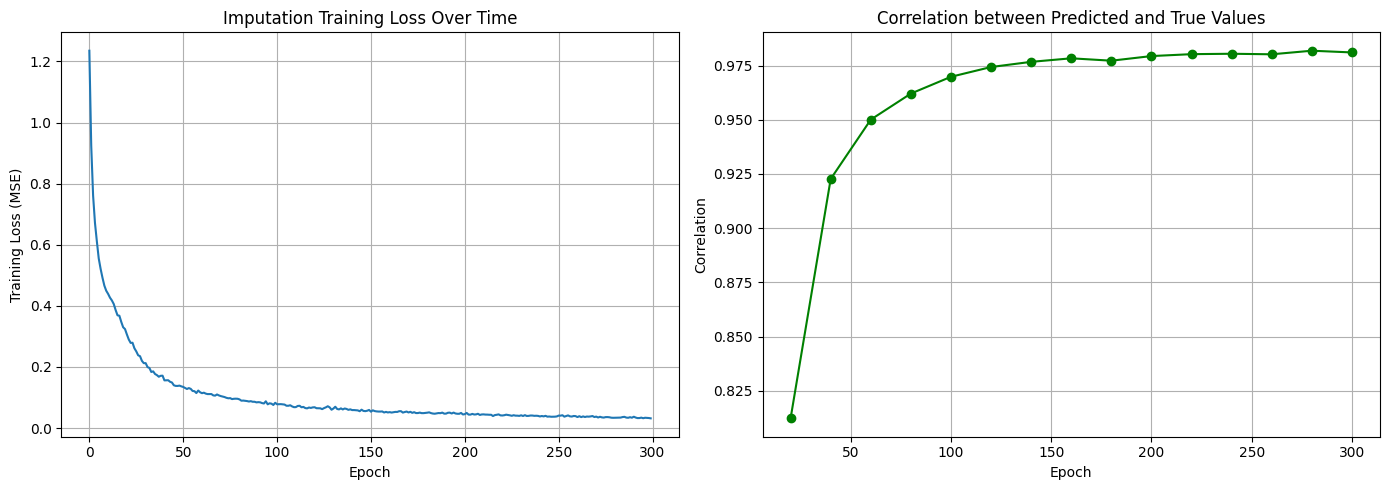

In [26]:
print("\n--- Training BetterGCN for imputation ---")
# Training loop
num_epochs_imputation = 300
imputation_losses = []
mse_scores = []
correlation_scores = []

for epoch in range(1, num_epochs_imputation + 1):
    loss = train_imputation(imputation_model, imputation_criterion, imputation_optimizer, imputation_data)
    imputation_losses.append(loss)

    if epoch % 20 == 0:
        mse, corr = evaluate_imputation(imputation_model, imputation_data)
        mse_scores.append(mse)
        correlation_scores.append(corr)

        print(f'Epoch: {epoch:03d}, Loss: {loss:.6f}, MSE: {mse:.6f}, Correlation: {corr:.4f}')

print(f"\n{'='*60}")
print(f"imputation training completed!")
print(f"{'='*60}")

# Visualize imputation training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(imputation_losses)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Training Loss (MSE)')
ax1.set_title('Imputation Training Loss Over Time')
ax1.grid(True)

epochs_recorded = list(range(20, num_epochs_imputation + 1, 20))
ax2.plot(epochs_recorded, correlation_scores, marker='o', color='green')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Correlation')
ax2.set_title('Correlation between Predicted and True Values')
ax2.grid(True)

plt.tight_layout()
plt.show()


In [27]:
imputation_model.eval()
with torch.no_grad():
    denoised_features = imputation_model(imputation_data.x, imputation_data.edge_index)

# Compute metrics
final_mse, final_corr = evaluate_imputation(imputation_model, imputation_data)

print(f"\nFinal imputation Performance:")
print(f"  MSE on masked values: {final_mse:.6f}")
print(f"  Correlation on masked values: {final_corr:.4f}")

# Visualize imputation results for a sample gene
sample_gene_idx = 0
sample_cell_indices = torch.where(imputation_data.mask[:, sample_gene_idx])[0][:100]

# Compare overall statistics
print("\n--- Overall Imputation Statistics ---")
print(f"Original mean (all values): {original_features.mean():.4f}")
print(f"Original std (all values): {original_features.std():.4f}")
print(f"Imputed mean (masked positions): {denoised_features[imputation_data.mask].mean():.4f}")
print(f"True mean (masked positions): {original_features[imputation_data.mask].mean():.4f}")


Final imputation Performance:
  MSE on masked values: 0.091924
  Correlation on masked values: 0.9811

--- Overall Imputation Statistics ---
Original mean (all values): 0.0494
Original std (all values): 0.2194
Imputed mean (masked positions): 0.7883
True mean (masked positions): 0.6593
